# M13.6 — Evaluación de la aumentación de ruido (val G3)

Entradas (solo lectura), en `<data_root>/results/M13_3/<tag>/`: `val_predictions_embeddings.npz` y `history.npz` de los modelos
de la celda de configuración; para la sección 7, además, `history.npz` de G1 (`M13_3a_R1/R2/R3`) si existen. Escalador train-only
y split del contrato congelado G1 (`g1_npe_contract.load_contract`, config M11). Del HDF5 trainio de G3 solo se leen
`mass_1, mass_2, spin_1z, spin_2z, target_network_snr, file_group_id` en las filas de val. Ni X, ni cal ni test.

Criterios fijados en `docs/experiments/M13_6_noise_augmentation.md` §7 (28-10-2026, antes de entrenar). Convenciones como en
`M13_3b_4a_evaluation`: etiquetas [chirp_mass, total_mass, chi_eff]; unidades físicas; r = f − θ; “media 3b” = media de las
métricas de M13_3b s123/s124; “media 6a” = media de las semillas de M13_6a disponibles. Épocas 0-based. Los IC son bootstrap
emparejado por filas de val: miden **muestreo de filas, no variación entre semillas**. Solo validación.

Reejecutable: los modelos opcionales sin npz final se omiten con aviso; cada ejecución escribe un resumen nuevo
`<data_root>/results/M13_3/M13_6_evaluation_summary_<YYYYmmdd_HHMM>.json` (modo `'x'`).

In [1]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
# Read-only reuse: pinned G1 contract, exact C3 implementation of M12.5.3, tau30/f220 of M13.1.
from scripts.m12.m12_5_3_posthoc_check import (
    ALPHAS, FAMILY_ALPHA, LABELS, MARGIN_FRAC, bootstrap_means, decide, digest, load_contract, npz_to_physical,
    require, ridge_paths, select_inner, slope_row)
from scripts.m13.m13_1_diagnostics import chirp_mass, f220_hz, tau_newtonian

# ---- Configuration -------------------------------------------------------------------------------------------
# (key, results tag, noise-augmented, required). An optional model whose final val npz does not exist is skipped
# with a warning; a missing required model aborts. Config file: configs/experiments/m13/train_m<tag[1:]>.json.
MODEL_SPECS = [
    ('3b_s123', 'M13_3b_G3_s123', False, True),
    ('3b_s124', 'M13_3b_G3_s124', False, True),
    ('4a_s123', 'M13_4a_G3_s123', False, True),
    ('6a_s123', 'M13_6a_G3aug_s123', True, True),
    ('6a_s124', 'M13_6a_G3aug_s124', True, False),
    ('4a_aug', 'M13_4a_G3aug_s123', True, True),
    ('4b_aug', 'M13_4b_G3aug_s123', True, False),
]
G1_HIST_SPECS = [('R1', 'M13_3a_R1_s123'), ('R2', 'M13_3a_R2_s123'), ('R3', 'M13_3a_R3_s124')]  # section 7 only, optional

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
VAL_NPZ, HIST_NPZ = 'val_predictions_embeddings.npz', 'history.npz'


def config_of(tag):
    return json.loads((ROOT / 'configs/experiments/m13' / f'train_m{tag[1:]}.json').read_text())


AVAILABLE, SKIPPED, TAG, AUG = [], [], {}, {}
for key, tag, aug, req in MODEL_SPECS:
    if (M13_DIR / tag / VAL_NPZ).exists():
        AVAILABLE.append(key)
        TAG[key], AUG[key] = tag, aug
    else:
        require(not req, f'Required model {key}: missing {M13_DIR / tag / VAL_NPZ}')
        SKIPPED.append(key)
        warnings.warn(f'Optional model {key} ({tag}) skipped: {VAL_NPZ} not found')
B3 = ['3b_s123', '3b_s124']                                       # M13.3b seed pair (no augmentation)
A6 = [m for m in ('6a_s123', '6a_s124') if m in AVAILABLE]       # M13.6a seeds available
ARCH = [m for m in ('4a_aug', '4b_aug') if m in AVAILABLE]       # architectures with augmentation
NOAUG_4A = '4a_s123'

# Fixed settings (prompt M13.6 evaluation; criteria from M13_6 doc §7).
Y_RTOL = 1e-5                      # y equality: |dy| <= rtol*|y| + rtol*y_std (float32 round trip)
N_BOOT = 2000
SEED_GLOBAL, SEED_TAU, SEED_BAND = 137001, 137002, 137003
RESOLVE_K = 2.0                    # resolved if |delta| > 2 * seed noise
SAFEGUARD_PCT = 2.0                # P-AUG3 safeguard: delta RMSE <= +2 % in every label
PAUG1_MIN, PAUG2_MAX_PCT = 0.95, 0.5
C3_N_BOOT, C3_SEED = 2000, 125301  # M12.5.3 protocol
C3_MODELS = [m for m in ('6a_s123', '4a_aug') if m in AVAILABLE]
MIN_GROUP_N = 200                  # flag only (as in M13.1); groups are never dropped
SNR_EDGES = np.linspace(10.0, 25.0, 6)               # 5 equal-width bins, last closed
MTOT_EDGES = [10.0, 30.0, 50.0, 80.0, 120.0, 180.0]  # last bin closed
EPOCHS_K = [0, 1, 2, 5, 10, 20, 40, 63, 79]
META = ['mass_1', 'mass_2', 'spin_1z', 'spin_2z', 'target_network_snr', 'file_group_id']
COLORS = {'3b': 'tab:blue', '6a': 'tab:green', '3b_s123': 'tab:blue', '3b_s124': 'tab:purple', '4a_s123': 'tab:orange',
          '6a_s123': 'tab:green', '6a_s124': 'tab:olive', '4a_aug': 'tab:red', '4b_aug': 'tab:brown',
          '6a_vs_3b': 'tab:green', '4a_aug_vs_6a': 'tab:red', '4b_aug_vs_6a': 'tab:brown', '4a_aug_vs_4a': 'tab:pink'}

print(DATA_ROOT)
print('models used:', {m: TAG[m] for m in AVAILABLE})
print('skipped (optional):', SKIPPED)

/data/vserrano/cbc_pe_data
models used: {'3b_s123': 'M13_3b_G3_s123', '3b_s124': 'M13_3b_G3_s124', '4a_s123': 'M13_4a_G3_s123', '6a_s123': 'M13_6a_G3aug_s123', '4a_aug': 'M13_4a_G3aug_s123'}
skipped (optional): ['6a_s124', '4b_aug']


/tmp/ipykernel_88280/740192684.py:55: UserWarning: Optional model 6a_s124 (M13_6a_G3aug_s124) skipped: val_predictions_embeddings.npz not found
  warnings.warn(f'Optional model {key} ({tag}) skipped: {VAL_NPZ} not found')
/tmp/ipykernel_88280/740192684.py:55: UserWarning: Optional model 4b_aug (M13_4b_G3aug_s123) skipped: val_predictions_embeddings.npz not found
  warnings.warn(f'Optional model {key} ({tag}) skipped: {VAL_NPZ} not found')


## 0. Integridad
Configs: mismo bloque `dataset` (G3) en todos, split y estadísticas train-only de M11, `checkpoint_tag` = tag y
`noise_augmentation.enabled` según el régimen. SHA256 de cada npz/history. Por npz: orden de etiquetas, split, `dataset_path` =
HDF5 de G3, `y_mean/y_std` = escalador train-only de M11, `idx` sin duplicados, valores finitos. **Mismas `idx` de val y misma `y`
en todos los modelos**; metadatos de val del HDF5 G3 reproducen `y`. Cualquier fallo aborta. Filas ordenadas por `idx` ascendente.

In [2]:
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)']


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


cfgs = {m: config_of(TAG[m]) for m in AVAILABLE}
ds0 = cfgs[B3[0]]['dataset']
check(all(c['dataset'] == ds0 for c in cfgs.values()), 'all model configs share the G3 dataset block')
check(all(ds0[k] == cfg['dataset'][k] for k in ('split_file', 'label_stats_file')),
      'G3 configs use the M11 split / train-only label stats')
for m, c in cfgs.items():
    check(c['outputs']['checkpoint_tag'] == TAG[m], f'{m}: config checkpoint_tag == {TAG[m]}')
    aug_on = bool((c['training'].get('noise_augmentation') or {}).get('enabled', False))
    check(aug_on == AUG[m], f'{m}: noise_augmentation.enabled == {AUG[m]}')
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=ds0['dataset_id'], file_name=ds0['dataset_file'])

files = {}
for m in AVAILABLE:
    files[f'{m}_val'] = M13_DIR / TAG[m] / VAL_NPZ
    files[f'{m}_history'] = M13_DIR / TAG[m] / HIST_NPZ
G1_AVAILABLE = []
for k, tag in G1_HIST_SPECS:
    if (M13_DIR / tag / HIST_NPZ).exists():
        files[f'{k}_history'] = M13_DIR / tag / HIST_NPZ
        G1_AVAILABLE.append(k)
        TAG[k] = tag
    else:
        warnings.warn(f'G1 history {k} ({tag}) not found: omitted from section 7')
missing = [str(p) for p in list(files.values()) + [G3_H5] if not p.exists()]
require(not missing, f'Missing inputs: {missing}')
sha = {k: digest(p) for k, p in files.items()}


def load_pred(path, name):
    # model_config / input_normalization are object arrays and are never accessed.
    with np.load(path, allow_pickle=False) as a:
        f, y = (a[k].astype(np.float64) for k in ('pred_val', 'y_val'))
        emb = a['emb_val'].astype(np.float64)
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ds_name = Path(str(a['dataset_path'])).name if 'dataset_path' in a.files else None
        stats_name = Path(str(a['label_stats_path'])).name if 'label_stats_path' in a.files else None
    n = len(idx)
    check(f.shape == y.shape == (n, 3) and emb.shape[0] == n, f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    # y_mean/y_std are written from the same arrays stored in the checkpoint (train_m13_3.py).
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz/checkpoint y_mean/y_std equal M11 train-only label stats')
    # Augmented runs evaluate val on the original G3 memmap X, so dataset_path is the G3 HDF5 for every model.
    check(ds_name == G3_H5.name, f'{name}: dataset_path is the G3 HDF5')
    check(stats_name == paths['label_stats_file'].name, f'{name}: label_stats_path is the M11 stats file')
    check(len(np.unique(idx)) == n, f'{name}: idx without duplicates')
    check(all(np.isfinite(v).all() for v in (f, y, emb)), f'{name}: finite values')
    y, f, units = npz_to_physical(y, f, c_mean, c_std)
    check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y ({units})')
    o = np.argsort(idx)
    return dict(f=f[o], y=y[o], emb=emb[o], idx=idx[o], units=units)


val = {m: load_pred(files[f'{m}_val'], f'{m} val') for m in AVAILABLE}
IDX, Y = val[B3[0]]['idx'], val[B3[0]]['y']
check(np.array_equal(IDX, np.sort(splits['val'])), f'{B3[0]}: idx_val equals val membership')
for m in AVAILABLE:
    check(np.array_equal(val[m]['idx'], IDX), f'{m}: same val idx as {B3[0]}')
    dy = np.abs(val[m]['y'] - Y)
    print(f'{m}: max |y - y_ref| =', dy.max(0))
    check(np.all(dy <= Y_RTOL * np.abs(Y) + Y_RTOL * c_std), f'{m}: same val y as {B3[0]} (rtol {Y_RTOL:g})')
P = {m: val[m]['f'] for m in AVAILABLE}
EMB = {m: val[m]['emb'] for m in AVAILABLE}

hist = {}
for m in G1_AVAILABLE + AVAILABLE:
    with np.load(files[f'{m}_history'], allow_pickle=False) as a:
        hist[m] = {k: a[k] for k in a.files}
    h = hist[m]
    check(h['label_names'].tolist() == LABELS, f'{m}: history label order')
    E = len(h['epoch'])
    check(h['val_mse'].shape == h['train40k_mse'].shape == (E, 3) and h['val_loss'].shape == (E,),
          f'{m}: history shapes')
    check(len(np.unique(h['epoch'])) == E and np.isfinite(h['val_loss']).all(),
          f'{m}: history epochs unique, val_loss finite')
    print(f"{m}: epochs {int(h['epoch'][0])}..{int(h['epoch'][-1])}, "
          f"train40k evaluated at {int(np.isfinite(h['train40k_mse']).all(1).sum())} epochs")

# Per-row metadata: only the listed G3 HDF5 columns, only at the (sorted) val rows.
with h5py.File(G3_H5, 'r') as h:
    missing = [k for k in META if k not in h]
    require(not missing, f'G3 HDF5 lacks metadata fields: {missing}')
    meta = {k: h[k][IDX] for k in META}
m1, m2, s1, s2, SNR = (meta[k].astype(np.float64) for k in META[:5])
ENV = meta['file_group_id']
check(all(np.isfinite(v).all() for v in (m1, m2, s1, s2, SNR)), 'G3 HDF5 metadata finite')
check(np.all((m1 > 0) & (m2 > 0)), 'component masses positive')
MTOT = m1 + m2
y_rec = np.column_stack([chirp_mass(m1, m2), MTOT, (m1 * s1 + m2 * s2) / MTOT])
print('max |y_rec - y| =', np.abs(y_rec - Y).max(0))
check(np.all(np.abs(y_rec - Y) <= Y_RTOL * np.abs(Y) + Y_RTOL * c_std),
      f'(Mc, M, chi_eff) from G3 HDF5 mass/spin equal val y of the npz (rtol {Y_RTOL:g})')
check(len(np.unique(ENV)) >= 3, 'at least 3 environments in val')
print('envs:', len(np.unique(ENV)), '| n_val:', len(Y))
pd.Series(sha, name='sha256').to_frame()

3b_s123: max |y - y_ref| = [0. 0. 0.]
3b_s124: max |y - y_ref| = [0. 0. 0.]
4a_s123: max |y - y_ref| = [0. 0. 0.]
6a_s123: max |y - y_ref| = [0. 0. 0.]
4a_aug: max |y - y_ref| = [0. 0. 0.]
R1: epochs 0..79, train40k evaluated at 80 epochs
R2: epochs 0..79, train40k evaluated at 80 epochs
R3: epochs 0..79, train40k evaluated at 80 epochs
3b_s123: epochs 0..79, train40k evaluated at 80 epochs
3b_s124: epochs 0..79, train40k evaluated at 80 epochs
4a_s123: epochs 0..79, train40k evaluated at 80 epochs
6a_s123: epochs 0..79, train40k evaluated at 80 epochs
4a_aug: epochs 0..79, train40k evaluated at 80 epochs
max |y_rec - y| = [5.68858736e-06 1.17017311e-05 9.06429227e-08]
envs: 3 | n_val: 40000


,sha256
3b_s123_val,be3d03179f60f370c3beac82ad6e39e3ed1a87046dcada...
3b_s123_history,44e434a4fecf79fb28e90e284bc5d6d211444ff1a6adba...
3b_s124_val,3e19282a500b21724547b2ca4dc4b2cd7355f15755a2bf...
3b_s124_history,01206cab542f0d04367e3da66a9699a1e33259c3de8d04...
4a_s123_val,998e554a3ad5f23963f07f533d71fc91c41c0a0a812f22...
4a_s123_history,a35e3ddd7c81037bdff98a492b728eade3208b89f87dec...
6a_s123_val,e4349bb067d2f02cd100c0ecf6309d516ac64d5c8e7662...
6a_s123_history,9f581e22dfb95701451b499437e8ac742d4e256353b5ed...
4a_aug_val,44ff7f540bef9c3f90989cb80701dd547b6ada70dea54f...
4a_aug_history,a49e974184969690a0b854eb3295675bca0f60aaf97d18...


## 1. Métricas por etiqueta (unidades físicas)
RMSE, MAE, R², pendiente θ sobre f y sesgo con signo en θ ≤ Q10 y θ ≥ Q90 (cuantiles de val) de todos los modelos.

**M13.6a frente a M13.3b:** ΔRMSE% = 100·(media RMSE 6a / media RMSE 3b − 1). Ruido de semilla (%): 100·|s123 − s124|/media del
par, para 3b y para 6a si existe s124; ruido usado = max de los disponibles; **resuelto** si |Δ| > 2·ruido. IC 95 % bootstrap
emparejado por filas (2000, semilla 137001; mismos remuestreos para todos los modelos): **muestreo de filas**. Si solo existe
6a s123, la “media 6a” es un único modelo y el ruido usado es solo el de 3b.

In [3]:
def label_metrics(f, y):
    rows = []
    for j, lab in enumerate(LABELS):
        e, s = f[:, j] - y[:, j], slope_row(f[:, j], y[:, j])
        q10, q90 = np.quantile(y[:, j], [0.1, 0.9])
        rows.append(dict(label=lab, rmse=np.sqrt(np.mean(e**2)), mae=np.mean(np.abs(e)), r2=s['r2'],
                         slope_theta_on_f=s['slope_truth_on_pred'],
                         intercept_theta_on_f=s['intercept_truth_on_pred'],
                         bias_Q10=e[y[:, j] <= q10].mean(), bias_Q90=e[y[:, j] >= q90].mean()))
    return rows


def boot_rmse(models, mask, n_boot, rng):
    """Point RMSE and paired row-bootstrap RMSE (n_boot, 3) within `mask`; same resamples for every model."""
    sel = np.flatnonzero(mask)
    n = len(sel)
    se = {m: (P[m][sel] - Y[sel])**2 for m in models}
    out = {m: np.empty((n_boot, 3)) for m in models}
    for start in range(0, n_boot, 50):
        b = min(50, n_boot - start)
        w = rng.multinomial(n, np.full(n, 1.0 / n), size=b).astype(np.float64)
        for m in models:
            out[m][start:start + b] = np.sqrt(w @ se[m] / n)
    return {m: np.sqrt(se[m].mean(0)) for m in models}, out


def delta_pct(rm, num, den):
    """100*(mean RMSE of `num` / mean RMSE of `den` - 1); works on (3,) points and (B, 3) resamples."""
    return 100.0 * (np.mean([rm[m] for m in num], 0) / np.mean([rm[m] for m in den], 0) - 1.0)


def seed_noise_pct(rm, pair):
    return 100.0 * np.abs(rm[pair[0]] - rm[pair[1]]) / np.mean([rm[m] for m in pair], 0)


tab1 = pd.DataFrame([dict(model=m, tag=TAG[m], augmented=AUG[m], **row)
                     for m in AVAILABLE for row in label_metrics(P[m], Y)])

# Multinomial draws depend only on n and the generator, so the resamples do not change with the model list.
rm, rb = boot_rmse(AVAILABLE, np.ones(len(Y), bool), N_BOOT, np.random.default_rng(SEED_GLOBAL))
noise_3b = seed_noise_pct(rm, B3)
noise_6a = seed_noise_pct(rm, A6) if len(A6) == 2 else np.full(3, np.nan)
NOISE = np.fmax(noise_3b, noise_6a)  # fmax ignores the NaN of a missing 6a seed pair


def comparison_rows(name, num, den):
    d, db = delta_pct(rm, num, den), delta_pct(rb, num, den)
    lo, hi = np.percentile(db, [2.5, 97.5], axis=0)
    rows = []
    for j, lab in enumerate(LABELS):
        resolved = bool(abs(d[j]) > RESOLVE_K * NOISE[j])
        rows.append(dict(comparison=name, num='+'.join(num), den='+'.join(den), label=lab, delta_rmse_pct=d[j],
                         ci95_lo_pct=lo[j], ci95_hi_pct=hi[j], noise_3b_pct=noise_3b[j], noise_6a_pct=noise_6a[j],
                         noise_used_pct=NOISE[j], resolved=resolved, improved_resolved=resolved and d[j] < 0,
                         safeguard=bool(d[j] <= SAFEGUARD_PCT), uncertainty='row sampling (val), not seed'))
    return rows


tab1_cmp = pd.DataFrame(comparison_rows('6a_vs_3b', A6, B3))
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab1)
    display(tab1_cmp)

,model,tag,augmented,label,rmse,mae,r2,slope_theta_on_f,intercept_theta_on_f,bias_Q10,bias_Q90
0,3b_s123,M13_3b_G3_s123,False,chirp_mass,5.2461,3.4458,0.89909,0.98454,0.68717,0.64156,-3.3922
1,3b_s123,M13_3b_G3_s123,False,total_mass,9.2072,6.5364,0.92957,0.99093,0.89674,2.2642,-6.1256
2,3b_s123,M13_3b_G3_s123,False,chi_eff,0.18266,0.1354,0.82688,0.97889,0.00042077,0.15646,-0.10722
3,3b_s124,M13_3b_G3_s124,False,chirp_mass,5.1748,3.4133,0.90182,0.98553,0.61347,0.62489,-3.3403
4,3b_s124,M13_3b_G3_s124,False,total_mass,9.1076,6.4875,0.93109,0.99104,0.86197,2.1963,-6.0029
5,3b_s124,M13_3b_G3_s124,False,chi_eff,0.18162,0.13444,0.82884,0.9803,4.5584e-05,0.15572,-0.10747
6,4a_s123,M13_4a_G3_s123,False,chirp_mass,5.329,3.4522,0.89588,0.97678,0.97251,0.58811,-3.2557
7,4a_s123,M13_4a_G3_s123,False,total_mass,9.3085,6.5398,0.92802,0.98595,1.4014,1.9877,-5.7893
8,4a_s123,M13_4a_G3_s123,False,chi_eff,0.18204,0.13467,0.82804,0.9687,0.00021817,0.14812,-0.098115
9,6a_s123,M13_6a_G3aug_s123,True,chirp_mass,4.8992,3.2638,0.912,0.99958,0.10693,0.60356,-3.4436


,comparison,num,den,label,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct,noise_3b_pct,noise_6a_pct,noise_used_pct,resolved,improved_resolved,safeguard,uncertainty
0,6a_vs_3b,6a_s123,3b_s123+3b_s124,chirp_mass,-5.9735,-6.556,-5.4046,1.3681,NaN,1.3681,True,True,True,"row sampling (val), not seed"
1,6a_vs_3b,6a_s123,3b_s123+3b_s124,total_mass,-5.8206,-6.3186,-5.3036,1.0871,NaN,1.0871,True,True,True,"row sampling (val), not seed"
2,6a_vs_3b,6a_s123,3b_s123+3b_s124,chi_eff,-5.6526,-6.1435,-5.1526,0.57079,NaN,0.57079,True,True,True,"row sampling (val), not seed"


## 2. Criterios P-AUG (doc M13.6 §7)
- **P-AUG1:** MSE_train40k / MSE_val (unidades estandarizadas, `history.npz`) en la última época con train40k evaluado (NaN
  ignorados; el entrenador siempre evalúa train40k en la última época), **≥ 0,95 en las tres etiquetas**. El train40k usa el ruido
  original de G3, nunca visto con aumentación.
- **P-AUG2:** `val_loss` final ≤ 0,5 % peor que la mejor época: 100·(final/mejor − 1) ≤ 0,5.
- **P-AUG3:** frente a la media de M13.3b, mejora resuelta (Δ < 0 y |Δ| > 2·ruido) en ≥ 1 etiqueta y ΔRMSE ≤ +2 % en todas.

Filas por modelo con aumentación (P-AUG3 del modelo individual frente a la media 3b, mismo ruido de la sección 1) y una fila
**decisiva** `6a (media)`: P-AUG1/2 deben pasar en todas las semillas de 6a disponibles y P-AUG3 es la comparación de la sección 1.
Figura: MSE de val (continua) y train40k (puntos) por época, y cociente train40k/val con la línea 0,95.

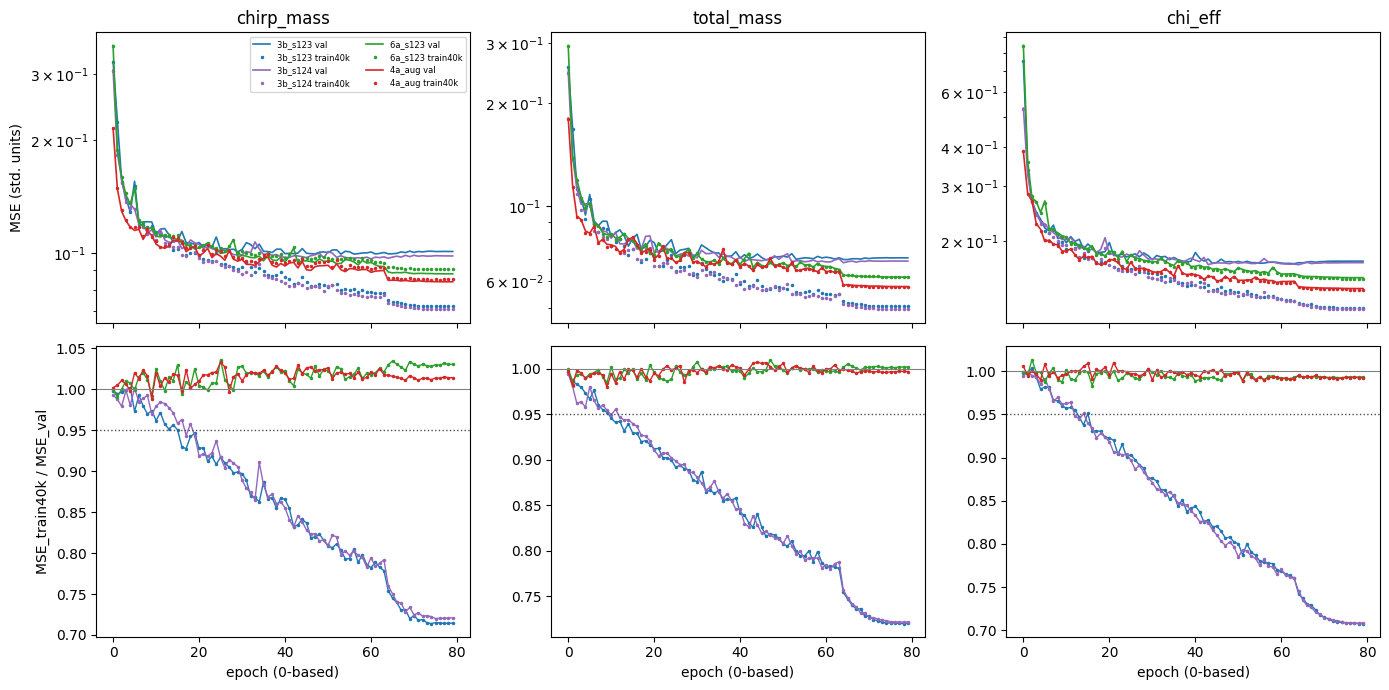

,model,decisive,paug1_epoch,paug1_is_last_epoch,paug1_ratio_chirp_mass,paug1_ratio_total_mass,paug1_ratio_chi_eff,paug1,best_val_epoch,final_epoch,final_vs_best_pct,paug2,paug3_delta_chirp_mass,paug3_delta_total_mass,paug3_delta_chi_eff,paug3,verdict
0,6a_s123,False,79,True,1.0303,1.0019,0.99324,PASA,79,79,0,PASA,-5.9735,-5.8206,-5.6526,PASA,PASA
1,4a_aug,False,79,True,1.014,0.99704,0.99251,PASA,78,79,0.00015921,PASA,-8.2336,-8.7752,-9.3695,PASA,PASA
2,6a (media: 6a_s123),True,NaN,NaN,NaN,NaN,NaN,PASA,NaN,NaN,NaN,PASA,-5.9735,-5.8206,-5.6526,PASA,PASA


,comparison,num,den,label,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct,noise_3b_pct,noise_6a_pct,noise_used_pct,resolved,improved_resolved,safeguard,uncertainty
0,6a_s123_vs_3b,6a_s123,3b_s123+3b_s124,chirp_mass,-5.9735,-6.556,-5.4046,1.3681,NaN,1.3681,True,True,True,"row sampling (val), not seed"
1,6a_s123_vs_3b,6a_s123,3b_s123+3b_s124,total_mass,-5.8206,-6.3186,-5.3036,1.0871,NaN,1.0871,True,True,True,"row sampling (val), not seed"
2,6a_s123_vs_3b,6a_s123,3b_s123+3b_s124,chi_eff,-5.6526,-6.1435,-5.1526,0.57079,NaN,0.57079,True,True,True,"row sampling (val), not seed"
3,4a_aug_vs_3b,4a_aug,3b_s123+3b_s124,chirp_mass,-8.2336,-8.8879,-7.5939,1.3681,NaN,1.3681,True,True,True,"row sampling (val), not seed"
4,4a_aug_vs_3b,4a_aug,3b_s123+3b_s124,total_mass,-8.7752,-9.3554,-8.2105,1.0871,NaN,1.0871,True,True,True,"row sampling (val), not seed"
5,4a_aug_vs_3b,4a_aug,3b_s123+3b_s124,chi_eff,-9.3695,-9.9291,-8.8153,0.57079,NaN,0.57079,True,True,True,"row sampling (val), not seed"


In [4]:
def paug3(rows):
    return bool(any(r['improved_resolved'] for r in rows) and all(r['safeguard'] for r in rows))


AUG_MODELS = [m for m in AVAILABLE if AUG[m]]
rows, rows_cmp2 = [], []
for m in AUG_MODELS:
    h = hist[m]
    fin = np.flatnonzero(np.isfinite(h['train40k_mse']).all(1))
    require(fin.size > 0, f'{m}: no epoch with train40k MSE')
    i = int(fin[-1])
    ratio = h['train40k_mse'][i] / h['val_mse'][i]
    ib = int(np.argmin(h['val_loss']))
    fin_vs_best = 100.0 * (h['val_loss'][-1] / h['val_loss'][ib] - 1.0)
    cmp_rows = comparison_rows(f'{m}_vs_3b', [m], B3)
    rows_cmp2 += cmp_rows
    rows.append(dict(model=m, decisive=False, paug1_epoch=int(h['epoch'][i]), paug1_is_last_epoch=i == len(h['epoch']) - 1,
                     **{f'paug1_ratio_{lab}': ratio[j] for j, lab in enumerate(LABELS)},
                     paug1=bool(np.all(ratio >= PAUG1_MIN)),
                     best_val_epoch=int(h['epoch'][ib]), final_epoch=int(h['epoch'][-1]), final_vs_best_pct=fin_vs_best,
                     paug2=bool(fin_vs_best <= PAUG2_MAX_PCT),
                     **{f'paug3_delta_{r["label"]}': r['delta_rmse_pct'] for r in cmp_rows}, paug3=paug3(cmp_rows)))
t6 = [r for r in rows if r['model'] in A6]
rows.append(dict(model='6a (media: ' + '+'.join(A6) + ')', decisive=True,
                 paug1=all(r['paug1'] for r in t6), paug2=all(r['paug2'] for r in t6),
                 **{f'paug3_delta_{r["label"]}': r['delta_rmse_pct'] for r in tab1_cmp.to_dict('records')},
                 paug3=paug3(tab1_cmp.to_dict('records'))))
tab2 = pd.DataFrame(rows)
tab2['verdict'] = np.where(tab2[['paug1', 'paug2', 'paug3']].all(axis=1), 'PASA', 'FALLA')
for c in ('paug1', 'paug2', 'paug3'):
    tab2[c] = np.where(tab2[c], 'PASA', 'FALLA')
tab2_cmp = pd.DataFrame(rows_cmp2)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for m in B3 + AUG_MODELS:
    h, ep = hist[m], hist[m]['epoch']
    for j in range(3):
        ok = np.isfinite(h['train40k_mse'][:, j])
        axes[0, j].plot(ep, h['val_mse'][:, j], '-', color=COLORS[m], lw=1.2, label=f'{m} val')
        axes[0, j].plot(ep[ok], h['train40k_mse'][ok, j], '.', color=COLORS[m], ms=3, label=f'{m} train40k')
        axes[1, j].plot(ep[ok], h['train40k_mse'][ok, j] / h['val_mse'][ok, j], '.-', color=COLORS[m], lw=1.0, ms=3)
for j, lab in enumerate(LABELS):
    axes[0, j].set(title=lab, yscale='log')
    axes[1, j].axhline(PAUG1_MIN, color='0.3', ls=':', lw=1)
    axes[1, j].axhline(1.0, color='0.5', lw=0.8)
    axes[1, j].set(xlabel='epoch (0-based)')
axes[0, 0].set_ylabel('MSE (std. units)')
axes[1, 0].set_ylabel('MSE_train40k / MSE_val')
axes[0, 0].legend(fontsize=6, ncol=2)
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 250):
    display(tab2)
    display(tab2_cmp)

## 3. Arquitecturas con aumentación
Comparaciones (misma regla de resolución que la sección 1, mismo ruido y mismos remuestreos, semilla 137001): M13.4a-aug y
M13.4b-aug (si existe) frente a la media 6a; M13.4a-aug frente a M13.4a sin aumentación (ambos s123).

**HIP-CONTEXTO:** τ30 newtoniano de la M_c verdadera y deciles como en M13.1 (D1 = τ más corto). Por decil, ΔRMSE% = 100·(RMSE
modelo / media RMSE 6a − 1) con IC bootstrap emparejado dentro del decil (semilla 137002; un generador recorrido por decil, con
los mismos remuestreos para todos los modelos). Contraste: media de D8–D10 menos media de D1–D3 de ΔRMSE% de χ_eff. **APOYA** si
es negativa y su IC excluye 0; si no, **NO APOYA**.

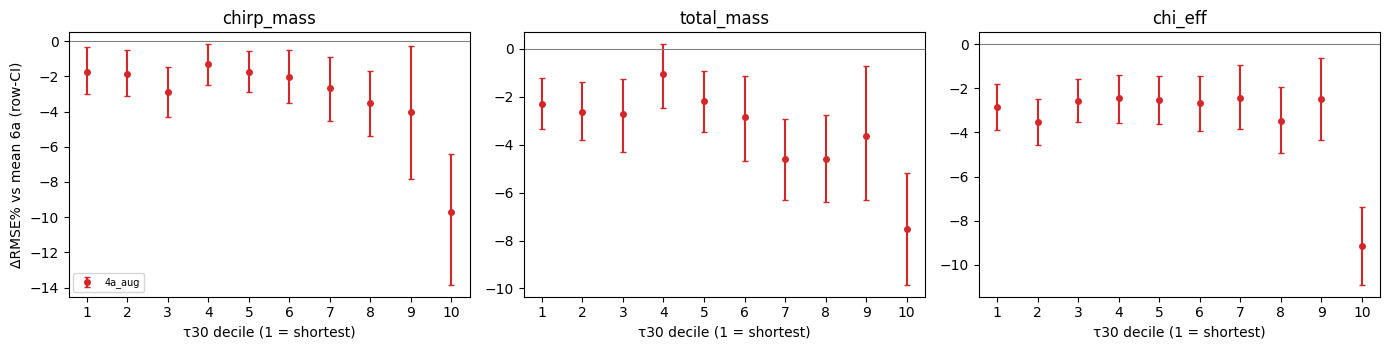

,comparison,num,den,label,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct,noise_3b_pct,noise_6a_pct,noise_used_pct,resolved,improved_resolved,safeguard,uncertainty
0,4a_aug_vs_6a,4a_aug,6a_s123,chirp_mass,-2.4037,-2.9274,-1.882,1.3681,NaN,1.3681,False,False,True,"row sampling (val), not seed"
1,4a_aug_vs_6a,4a_aug,6a_s123,total_mass,-3.1372,-3.6281,-2.6285,1.0871,NaN,1.0871,True,True,True,"row sampling (val), not seed"
2,4a_aug_vs_6a,4a_aug,6a_s123,chi_eff,-3.9396,-4.4271,-3.4506,0.57079,NaN,0.57079,True,True,True,"row sampling (val), not seed"
3,4a_aug_vs_4a,4a_aug,4a_s123,chirp_mass,-10.275,-11.17,-9.3859,1.3681,NaN,1.3681,True,True,True,"row sampling (val), not seed"
4,4a_aug_vs_4a,4a_aug,4a_s123,total_mass,-10.256,-11.075,-9.442,1.0871,NaN,1.0871,True,True,True,"row sampling (val), not seed"
5,4a_aug_vs_4a,4a_aug,4a_s123,chi_eff,-9.3228,-9.9604,-8.6703,0.57079,NaN,0.57079,True,True,True,"row sampling (val), not seed"


,model,label,tau_decile,tau_lo_s,tau_hi_s,n,rmse_model,rmse_6a,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct
2,4a_aug,chi_eff,1,0.052278,0.078744,4000,0.18254,0.18789,-2.8518,-3.8993,-1.8043
5,4a_aug,chi_eff,2,0.078744,0.099333,4000,0.16857,0.17469,-3.5045,-4.5791,-2.5004
8,4a_aug,chi_eff,3,0.099333,0.1223,4000,0.16314,0.16743,-2.5656,-3.532,-1.5534
11,4a_aug,chi_eff,4,0.1223,0.15126,4000,0.15406,0.15793,-2.4518,-3.5559,-1.3902
14,4a_aug,chi_eff,5,0.15126,0.1894,4000,0.15289,0.15686,-2.5332,-3.5967,-1.4435
17,4a_aug,chi_eff,6,0.1894,0.24407,4000,0.14519,0.14916,-2.6572,-3.9141,-1.4385
20,4a_aug,chi_eff,7,0.24407,0.3249,4000,0.14923,0.15292,-2.4139,-3.8482,-0.92988
23,4a_aug,chi_eff,8,0.3249,0.45347,4000,0.15154,0.157,-3.4763,-4.9405,-1.9478
26,4a_aug,chi_eff,9,0.45347,0.70688,4000,0.15904,0.16305,-2.4644,-4.3323,-0.62146
29,4a_aug,chi_eff,10,0.70688,5.8918,4000,0.21312,0.23457,-9.1447,-10.908,-7.37


4a_aug: chi_eff mean(D8-D10) - mean(D1-D3) = -2.054 % [-3.183, -0.8662] -> APOYA


In [5]:
rows = []
for a in ARCH:
    rows += comparison_rows(f'{a}_vs_6a', [a], A6)
if '4a_aug' in ARCH:
    rows += comparison_rows('4a_aug_vs_4a', ['4a_aug'], [NOAUG_4A])
tab3_cmp = pd.DataFrame(rows)

tau30 = tau_newtonian(Y[:, 0])
tau_edges = np.quantile(tau30, np.linspace(0, 1, 11))
tdec = np.clip(np.searchsorted(tau_edges[1:-1], tau30, side='right'), 0, 9)
rng = np.random.default_rng(SEED_TAU)
rows, dboot = [], {a: np.empty((10, N_BOOT, 3)) for a in ARCH}
for d in range(10):
    g = tdec == d
    pt, bt = boot_rmse(A6 + ARCH, g, N_BOOT, rng)
    for a in ARCH:
        dp, dboot[a][d] = delta_pct(pt, [a], A6), delta_pct(bt, [a], A6)
        lo, hi = np.percentile(dboot[a][d], [2.5, 97.5], axis=0)
        for j, lab in enumerate(LABELS):
            rows.append(dict(model=a, label=lab, tau_decile=d + 1, tau_lo_s=tau_edges[d], tau_hi_s=tau_edges[d + 1],
                             n=int(g.sum()), rmse_model=pt[a][j], rmse_6a=np.mean([pt[m][j] for m in A6]),
                             delta_rmse_pct=dp[j], ci95_lo_pct=lo[j], ci95_hi_pct=hi[j]))
tab3_tau = pd.DataFrame(rows)

J = LABELS.index('chi_eff')
LONG, SHORT = [7, 8, 9], [0, 1, 2]
hip_ctx = {}
for a in ARCH:
    d_chi = tab3_tau[(tab3_tau.model == a) & (tab3_tau.label == 'chi_eff')].sort_values('tau_decile').delta_rmse_pct.to_numpy()
    diff = d_chi[LONG].mean() - d_chi[SHORT].mean()
    lo, hi = np.percentile(dboot[a][LONG, :, J].mean(0) - dboot[a][SHORT, :, J].mean(0), [2.5, 97.5])
    hip_ctx[a] = dict(reading='APOYA' if (diff < 0 and hi < 0) else 'NO APOYA', chi_eff_long_minus_short_pct=diff,
                      ci95=[lo, hi], long=['D8', 'D9', 'D10'], short=['D1', 'D2', 'D3'], reference='6a mean')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
x = np.arange(1, 11)
for ax, lab in zip(axes, LABELS):
    for k, a in enumerate(ARCH):
        t = tab3_tau[(tab3_tau.model == a) & (tab3_tau.label == lab)]
        ax.errorbar(x + 0.15 * (k - (len(ARCH) - 1) / 2), t.delta_rmse_pct,
                    yerr=[t.delta_rmse_pct - t.ci95_lo_pct, t.ci95_hi_pct - t.delta_rmse_pct],
                    fmt='o', ms=4, color=COLORS[a], capsize=2, label=a)
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set(title=lab, xlabel='τ30 decile (1 = shortest)', xticks=x)
axes[0].set_ylabel('ΔRMSE% vs mean 6a (row-CI)')
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab3_cmp)
    display(tab3_tau[tab3_tau.label == 'chi_eff'])
for a, v in hip_ctx.items():
    print(f"{a}: chi_eff mean(D8-D10) - mean(D1-D3) = {v['chi_eff_long_minus_short_pct']:.4g} % "
          f"[{v['ci95'][0]:.4g}, {v['ci95'][1]:.4g}] -> {v['reading']}")

## 4. Por clase de f220 y bins de M_total
f220 como en M13.1 (`f220_hz`, χ1 = espín de la componente más pesada) a partir de la verdad de val. Clases: <256 (f < 256),
256–512 (256 ≤ f ≤ 512), 512–1024 (512 < f ≤ 1024), >1024 (f > 1024). Bins de M_total: [10,30), [30,50), [50,80), [80,120),
[120,180]. Por clase y etiqueta: ΔRMSE% de 6a (media) frente a 3b (media) y de cada arquitectura con aumentación frente a 6a, con
IC 95 % bootstrap emparejado dentro de la clase (semilla 137003; un generador recorrido en el orden de la tabla, mismos remuestreos
para todas las comparaciones de una clase). Clases con n < 200 se marcan, no se eliminan. **Descriptivo:** f220 correlaciona
fuertemente con la masa.

f220 clipped a_f / a_e: 35 0
rows outside M_total bins: 0


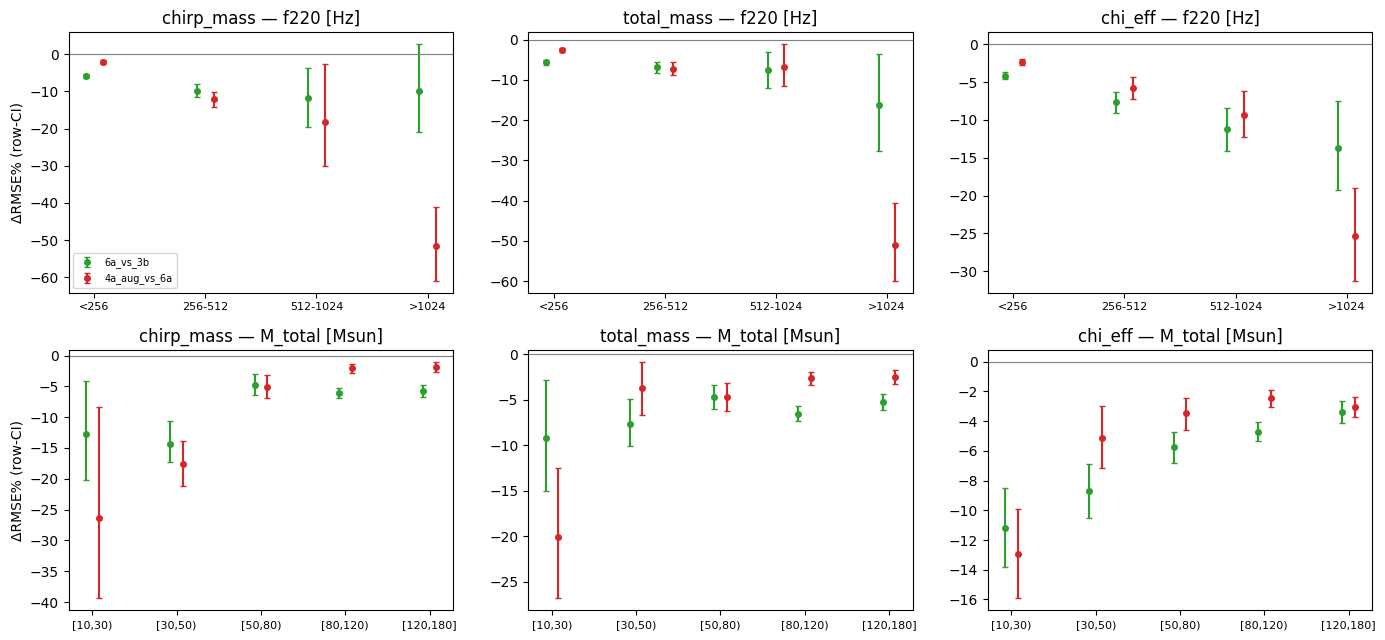

,grouping,cls,comparison,label,n,small,rmse_num,rmse_den,delta_rmse_pct,ci95_lo_pct,ci95_hi_pct
0,f220,<256,6a_vs_3b,chirp_mass,30680,False,5.5084,5.8501,-5.8412,-6.4739,-5.224
1,f220,<256,6a_vs_3b,total_mass,30680,False,9.1729,9.7182,-5.6111,-6.1994,-5.0037
2,f220,<256,6a_vs_3b,chi_eff,30680,False,0.16591,0.17313,-4.1668,-4.6159,-3.7141
3,f220,<256,4a_aug_vs_6a,chirp_mass,30680,False,5.3936,5.5084,-2.0826,-2.6385,-1.5575
4,f220,<256,4a_aug_vs_6a,total_mass,30680,False,8.9483,9.1729,-2.4487,-2.9806,-1.9287
5,f220,<256,4a_aug_vs_6a,chi_eff,30680,False,0.16192,0.16591,-2.4054,-2.8179,-1.9985
6,f220,256-512,6a_vs_3b,chirp_mass,7630,False,1.8685,2.0709,-9.7725,-11.405,-8.0735
7,f220,256-512,6a_vs_3b,total_mass,7630,False,6.5762,7.0604,-6.8576,-8.1475,-5.4775
8,f220,256-512,6a_vs_3b,chi_eff,7630,False,0.17158,0.18581,-7.6573,-9.0619,-6.3713
9,f220,256-512,4a_aug_vs_6a,chirp_mass,7630,False,1.6415,1.8685,-12.154,-14.244,-10.086


In [6]:
big = m1 >= m2
m_big, m_small = np.where(big, m1, m2), np.where(big, m2, m1)
chi_big, chi_small = np.where(big, s1, s2), np.where(big, s2, s1)
F220, a_f, m_f, n_af_clipped, n_ae_clipped = f220_hz(m_big, m_small, chi_big, chi_small)
check(np.all(np.isfinite(F220) & (F220 > 0)), 'f220 finite and positive')
print('f220 clipped a_f / a_e:', n_af_clipped, n_ae_clipped)

GROUPS = [('f220', '<256', F220 < 256.0), ('f220', '256-512', (F220 >= 256.0) & (F220 <= 512.0)),
          ('f220', '512-1024', (F220 > 512.0) & (F220 <= 1024.0)), ('f220', '>1024', F220 > 1024.0)]
for k, (lo, hi) in enumerate(zip(MTOT_EDGES[:-1], MTOT_EDGES[1:])):
    last = k == len(MTOT_EDGES) - 2
    GROUPS.append(('M_total', f'[{lo:g},{hi:g}{"]" if last else ")"}',
                   (MTOT >= lo) & ((MTOT <= hi) if last else (MTOT < hi))))
print('rows outside M_total bins:', int((~np.any([g for gr, _, g in GROUPS if gr == 'M_total'], 0)).sum()))

CMP4 = [('6a_vs_3b', A6, B3)] + [(f'{a}_vs_6a', [a], A6) for a in ARCH]
rng = np.random.default_rng(SEED_BAND)
rows = []
for grouping, cls, g in GROUPS:
    n = int(g.sum())
    if n == 0:
        rows += [dict(grouping=grouping, cls=cls, comparison=c[0], label=lab, n=0) for c in CMP4 for lab in LABELS]
        continue
    pt, bt = boot_rmse(B3 + A6 + ARCH, g, N_BOOT, rng)
    for name, num, den in CMP4:
        d, db = delta_pct(pt, num, den), delta_pct(bt, num, den)
        lo, hi = np.percentile(db, [2.5, 97.5], axis=0)
        for j, lab in enumerate(LABELS):
            rows.append(dict(grouping=grouping, cls=cls, comparison=name, label=lab, n=n, small=n < MIN_GROUP_N,
                             rmse_num=np.mean([pt[m][j] for m in num]), rmse_den=np.mean([pt[m][j] for m in den]),
                             delta_rmse_pct=d[j], ci95_lo_pct=lo[j], ci95_hi_pct=hi[j]))
tab4 = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for i, grouping in enumerate(('f220', 'M_total')):
    for j, lab in enumerate(LABELS):
        ax = axes[i, j]
        for k, (name, _, _) in enumerate(CMP4):
            t = tab4[(tab4.grouping == grouping) & (tab4.comparison == name) & (tab4.label == lab) & (tab4.n > 0)]
            x = np.arange(len(t))
            ax.errorbar(x + 0.15 * (k - (len(CMP4) - 1) / 2), t.delta_rmse_pct,
                        yerr=[t.delta_rmse_pct - t.ci95_lo_pct, t.ci95_hi_pct - t.delta_rmse_pct],
                        fmt='o', ms=4, color=COLORS[name], capsize=2, label=name)
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels(t.cls, fontsize=8)
        ax.set(title=f'{lab} — {grouping}' + (' [Hz]' if grouping == 'f220' else ' [Msun]'))
    axes[i, 0].set_ylabel('ΔRMSE% (row-CI)')
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab4)

## 5. Colas y SNR
Sesgo con signo (media de f − θ) en θ ≤ Q10 y θ ≥ Q90 (de la sección 1) por etiqueta; sesgo por decil de θ verdadero (bordes de val
comunes) y RMSE por 5 bins de SNR de igual anchura en [10, 25] (último cerrado; SNR = `target_network_snr` del HDF5 G3). Conjuntos:
3b (media s123/s124), 6a (media de las semillas disponibles) y cada arquitectura con aumentación. Media de las métricas por modelo.
Descriptivo.

rows outside SNR range: 0


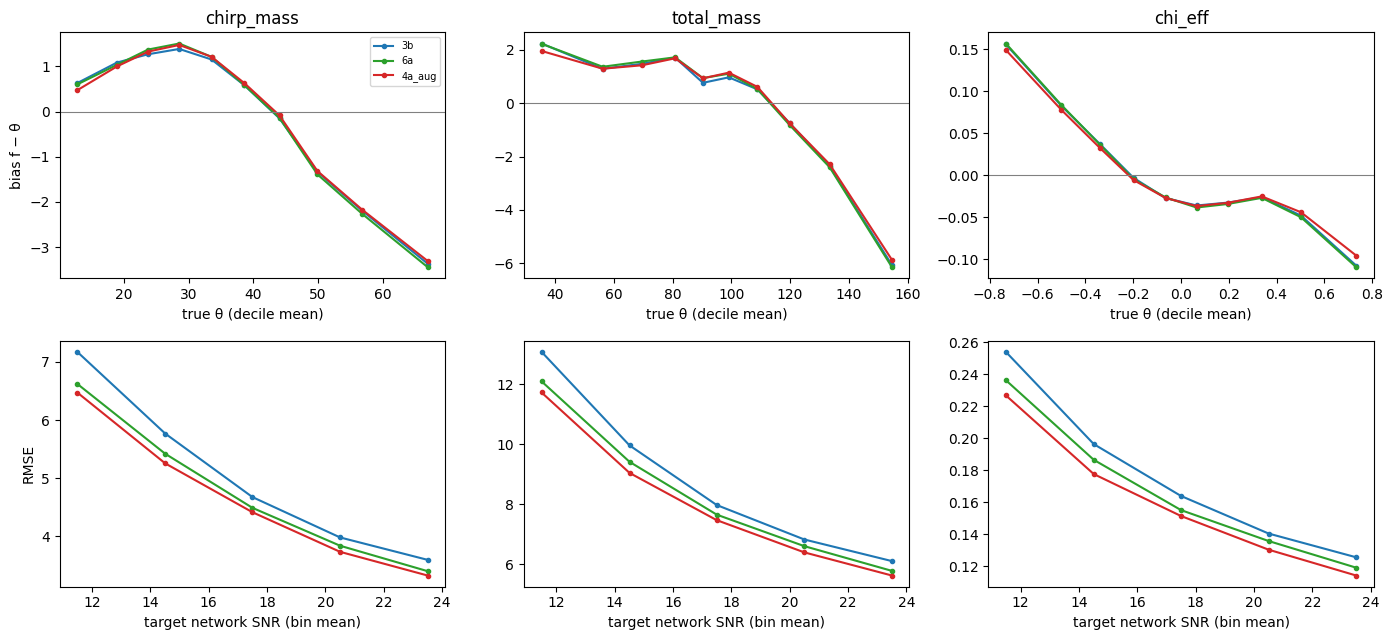

,set,label,bias_Q10,bias_Q90,slope_theta_on_f
0,3b,chirp_mass,0.63322,-3.3662,0.98504
1,3b,total_mass,2.2303,-6.0643,0.99098
2,3b,chi_eff,0.15609,-0.10735,0.9796
3,6a,chirp_mass,0.60356,-3.4436,0.99958
4,6a,total_mass,2.2202,-6.1444,1.0005
5,6a,chi_eff,0.15712,-0.10923,1.0038
6,4a_aug,chirp_mass,0.47483,-3.3059,0.99931
7,4a_aug,total_mass,1.9515,-5.8699,1.0001
8,4a_aug,chi_eff,0.1494,-0.095406,1.0026


,set,snr_bin,snr_center,n,chirp_mass,total_mass,chi_eff
0,3b,"[10,13)",11.496,8084,7.1729,13.076,0.254
1,3b,"[13,16)",14.51,8021,5.7667,9.9623,0.1963
2,3b,"[16,19)",17.499,7945,4.6744,7.9761,0.16385
3,3b,"[19,22)",20.502,8073,3.9801,6.8288,0.14034
4,3b,"[22,25]",23.503,7877,3.5944,6.11,0.12548
5,6a,"[10,13)",11.496,8084,6.6219,12.094,0.23628
6,6a,"[13,16)",14.51,8021,5.4195,9.4155,0.18646
7,6a,"[16,19)",17.499,7945,4.4892,7.6567,0.15502
8,6a,"[19,22)",20.502,8073,3.8374,6.6069,0.13566
9,6a,"[22,25]",23.503,7877,3.3997,5.7843,0.11899


In [7]:
SETS = {'3b': B3, '6a': A6, **{a: [a] for a in ARCH}}
tab5_tails = (pd.concat([tab1[tab1.model.isin(ms)].assign(set=s) for s, ms in SETS.items()])
              .groupby(['set', 'label'], sort=False)[['bias_Q10', 'bias_Q90', 'slope_theta_on_f']].mean().reset_index())

rows = []
for j, lab in enumerate(LABELS):
    edges = np.quantile(Y[:, j], np.linspace(0, 1, 11))
    dec = np.clip(np.searchsorted(edges[1:-1], Y[:, j], side='right'), 0, 9)
    for s, ms in SETS.items():
        for k in range(10):
            g = dec == k
            r = [P[m][g, j] - Y[g, j] for m in ms]
            rows.append(dict(set=s, label=lab, decile=k + 1, center=Y[g, j].mean(), n=int(g.sum()),
                             bias=np.mean([x.mean() for x in r]), rmse=np.mean([np.sqrt(np.mean(x**2)) for x in r])))
tab5_dec = pd.DataFrame(rows)

sbin = np.searchsorted(SNR_EDGES[1:-1], SNR, side='right')
in_range = (SNR >= SNR_EDGES[0]) & (SNR <= SNR_EDGES[-1])
print('rows outside SNR range:', int((~in_range).sum()))
rows = []
for s, ms in SETS.items():
    for b in range(len(SNR_EDGES) - 1):
        g = in_range & (sbin == b)
        rmse_b = np.mean([np.sqrt(np.mean((P[m][g] - Y[g])**2, axis=0)) for m in ms], 0)
        rows.append(dict(set=s, snr_bin=f'[{SNR_EDGES[b]:g},{SNR_EDGES[b + 1]:g}{"]" if b == 4 else ")"}',
                         snr_center=SNR[g].mean(), n=int(g.sum()), **dict(zip(LABELS, rmse_b))))
tab5_snr = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for j, lab in enumerate(LABELS):
    for s in SETS:
        t = tab5_dec[(tab5_dec.set == s) & (tab5_dec.label == lab)]
        axes[0, j].plot(t.center, t.bias, 'o-', ms=3, color=COLORS[s], label=s)
        t = tab5_snr[tab5_snr.set == s]
        axes[1, j].plot(t.snr_center, t[lab], 'o-', ms=3, color=COLORS[s])
    axes[0, j].axhline(0, color='0.5', lw=0.8)
    axes[0, j].set(title=lab, xlabel='true θ (decile mean)')
    axes[1, j].set(xlabel='target network SNR (bin mean)')
axes[0, 0].set_ylabel('bias f − θ')
axes[1, 0].set_ylabel('RMSE')
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab5_tails)
    display(tab5_snr)

## 6. C3 (ridge sobre el embedding), protocolo M12.5.3
Idéntico a M13_3a / M13_3b_4a (`ridge_paths`, `select_inner`): ridge sobre θ − f con entradas [emb, f], α ∈ {1e-2, …, 1e4} por
etiqueta por LOEO interno; LOEO externo por `file_group_id` (del HDF5 G3). Bootstrap pareado dentro de entorno (2000, semilla
125301), intervalo al 99,5833 % y margen del 1 %. Fracción de riesgo evitable = (MSE_modelo − MSE_C3)/MSE_modelo, para M13_6a s123
y M13.4a-aug. Exploratorio, ajustado en val.

In [8]:
def c3_loeo(f, y, emb, env):
    """Out-of-fold C3 predictions; identical to the C3 branch of m12_5_3 loeo_predictions."""
    z, r = np.hstack([emb, f]), y - f
    out, chosen = np.empty_like(y), []
    for e in np.unique(env):
        te, tr = env == e, env != e
        best, _ = select_inner(ridge_paths, z[tr], r[tr], env[tr])
        outer = ridge_paths(z[tr], r[tr], z[te])
        out[te] = f[te] + np.stack([outer[best[j], :, j] for j in range(len(LABELS))], 1)
        chosen.append(dict(heldout_env=str(e), **{lab: ALPHAS[best[j]] for j, lab in enumerate(LABELS)}))
    return out, chosen


rows, c3_alphas = [], {}
q_lo, q_hi = 100 * FAMILY_ALPHA / 2, 100 * (1 - FAMILY_ALPHA / 2)
for m in C3_MODELS:
    pc, c3_alphas[m] = c3_loeo(P[m], Y, EMB[m], ENV)
    e_m, e_c = (P[m] - Y)**2, (pc - Y)**2
    bm = bootstrap_means(e_m - e_c, ENV, {'global': np.ones(len(Y), bool)}, C3_N_BOOT, C3_SEED)['global']
    lo, hi = np.percentile(bm, [q_lo, q_hi], axis=0)
    for j, lab in enumerate(LABELS):
        mse_m, mse_c = e_m[:, j].mean(), e_c[:, j].mean()
        rows.append(dict(model=m, label=lab, mse_model=mse_m, mse_c3=mse_c, avoidable_frac=(mse_m - mse_c) / mse_m,
                         d_lo=lo[j], d_hi=hi[j], margin=MARGIN_FRAC * mse_m,
                         decision=decide(lo[j], hi[j], MARGIN_FRAC * mse_m)))
    print(f'{m} done', flush=True)
tab6 = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 200):
    display(tab6)

6a_s123 done
4a_aug done


,model,label,mse_model,mse_c3,avoidable_frac,d_lo,d_hi,margin,decision
0,6a_s123,chirp_mass,24.003,24.008,-0.00022957,-0.022472,0.010691,0.24003,NO_EVIDENCE_WITHIN_MARGIN
1,6a_s123,total_mass,74.38,74.414,-0.0004587,-0.068814,-0.0035054,0.7438,NO_EVIDENCE_WITHIN_MARGIN
2,6a_s123,chi_eff,0.02953,0.029537,-0.00025723,-2.4813e-05,1.0385e-05,0.0002953,NO_EVIDENCE_WITHIN_MARGIN
3,4a_aug,chirp_mass,22.863,22.872,-0.00042913,-0.027359,0.0069262,0.22863,NO_EVIDENCE_WITHIN_MARGIN
4,4a_aug,total_mass,69.786,69.822,-0.00051774,-0.07196,-0.0046652,0.69786,NO_EVIDENCE_WITHIN_MARGIN
5,4a_aug,chi_eff,0.027249,0.027263,-0.0005224,-3.0406e-05,1.2019e-06,0.00027249,NO_EVIDENCE_WITHIN_MARGIN


## 7. Orden temprano frente a final
`val_loss` (media del MSE estandarizado de val) de cada `history.npz` (modelos de la configuración y, si existen, M13_3a R1/R2/R3
de G1) en las épocas {0, 1, 2, 5, 10, 20, 40, 63, 79} (NaN si la época no existe), mejor época y final (= última fila). Por grupo
(`sin_aug`: todos los modelos sin aumentación, G1 y G3; `con_aug`; `G3`: todos los de G3, con y sin aumentación), Spearman entre el
orden de `val_loss` en la época k y el de la `val_loss` final, sobre los modelos con valor finito en k (rangos medios en empates;
NaN si n < 3). **n es muy pequeño: lectura descriptiva, sin inferencia.**

In [9]:
def val_at(h, e):
    i = np.flatnonzero(h['epoch'] == e)
    return float(h['val_loss'][i[0]]) if i.size else np.nan


def spearman(a, b):
    ra, rf = pd.Series(a).rank().to_numpy(), pd.Series(b).rank().to_numpy()
    if len(ra) < 3 or np.std(ra) == 0 or np.std(rf) == 0:
        return np.nan
    return float(np.corrcoef(ra, rf)[0, 1])


HIST_MODELS = G1_AVAILABLE + AVAILABLE
rows = []
for m in HIST_MODELS:
    h = hist[m]
    ib = int(np.argmin(h['val_loss']))
    rows.append(dict(model=m, tag=TAG[m], dataset='G1' if m in G1_AVAILABLE else 'G3', augmented=AUG.get(m, False),
                     **{f'val_e{k}': val_at(h, k) for k in EPOCHS_K},
                     best_epoch=int(h['epoch'][ib]), best_val=float(h['val_loss'][ib]),
                     final_epoch=int(h['epoch'][-1]), final_val=float(h['val_loss'][-1])))
tab7 = pd.DataFrame(rows).set_index('model')

REGIMES = {'sin_aug': [m for m in HIST_MODELS if not tab7.loc[m, 'augmented']],
           'con_aug': [m for m in HIST_MODELS if tab7.loc[m, 'augmented']],
           'G3': [m for m in HIST_MODELS if tab7.loc[m, 'dataset'] == 'G3']}
rows = []
for reg, ms in REGIMES.items():
    t = tab7.loc[ms]
    for k in EPOCHS_K:
        v = t[f'val_e{k}'].to_numpy()
        ok = np.isfinite(v)
        rows.append(dict(regime=reg, epoch=k, n=int(ok.sum()), models=','.join(t.index[ok]),
                         spearman_vs_final=spearman(v[ok], t['final_val'].to_numpy()[ok]),
                         note='descriptive: very small n'))
tab7_rho = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:.5g}'.format, 'display.width', 250):
    display(tab7)
    display(tab7_rho.pivot(index='epoch', columns='regime', values='spearman_vs_final'))
    display(tab7_rho)

,tag,dataset,augmented,val_e0,val_e1,val_e2,val_e5,val_e10,val_e20,val_e40,val_e63,val_e79,best_epoch,best_val,final_epoch,final_val
model,,,,,,,,,,,,,,,,
R1,M13_3a_R1_s123,G1,False,0.53031,0.27141,0.21305,0.17752,0.15886,0.14602,0.14059,0.13583,0.13627,66,0.1357,79,0.13627
R2,M13_3a_R2_s123,G1,False,0.47612,0.2518,0.21601,0.18039,0.15771,0.14606,0.13703,0.13493,0.13592,64,0.13397,79,0.13592
R3,M13_3a_R3_s124,G1,False,0.45068,0.25167,0.20725,0.17001,0.15042,0.14809,0.13741,0.13701,0.13773,64,0.13581,79,0.13773
3b_s123,M13_3b_G3_s123,G3,False,0.44536,0.24446,0.17917,0.16103,0.12996,0.12741,0.11777,0.11321,0.11448,62,0.11297,79,0.11448
3b_s124,M13_3b_G3_s124,G3,False,0.3626,0.21695,0.17894,0.1531,0.13092,0.12,0.11387,0.11202,0.11242,64,0.11088,79,0.11242
4a_s123,M13_4a_G3_s123,G3,False,0.25474,0.18418,0.15904,0.14109,0.12162,0.12148,0.11362,0.11465,0.11569,64,0.11195,79,0.11569
6a_s123,M13_6a_G3aug_s123,G3,True,0.4999,0.22979,0.18462,0.17318,0.13302,0.12019,0.10924,0.10466,0.10071,79,0.10071,79,0.10071
4a_aug,M13_4a_G3aug_s123,G3,True,0.26069,0.18236,0.16359,0.13231,0.12274,0.1141,0.10476,0.1008,0.094124,78,0.094124,79,0.094124


regime,G3,con_aug,sin_aug
epoch,,,
0,-0.3,NaN,0.65714
1,0.3,NaN,0.65714
2,-0.3,NaN,0.6
5,0.1,NaN,0.6
10,-0.4,NaN,0.6
20,0.8,NaN,0.88571
40,0.7,NaN,0.77143
63,1,NaN,1
79,1,NaN,1


,regime,epoch,n,models,spearman_vs_final,note
0,sin_aug,0,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",0.65714,descriptive: very small n
1,sin_aug,1,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",0.65714,descriptive: very small n
2,sin_aug,2,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",0.6,descriptive: very small n
3,sin_aug,5,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",0.6,descriptive: very small n
4,sin_aug,10,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",0.6,descriptive: very small n
5,sin_aug,20,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",0.88571,descriptive: very small n
6,sin_aug,40,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",0.77143,descriptive: very small n
7,sin_aug,63,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",1,descriptive: very small n
8,sin_aug,79,6,"R1,R2,R3,3b_s123,3b_s124,4a_s123",1,descriptive: very small n
9,con_aug,0,2,"6a_s123,4a_aug",NaN,descriptive: very small n


## 8. Resumen
Todas las lecturas en `<data_root>/results/M13_3/M13_6_evaluation_summary_<YYYYmmdd_HHMM>.json` (modo `'x'`: una ejecución nueva
genera un fichero nuevo; dos ejecuciones en el mismo minuto abortan en lugar de sobrescribir).

In [10]:
def to_json(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def by_label(t):
    return {r['label']: {k: r[k] for k in ('delta_rmse_pct', 'ci95_lo_pct', 'ci95_hi_pct', 'noise_used_pct', 'resolved',
                                           'improved_resolved', 'safeguard')}
            for r in t.to_dict('records')}


stamp = datetime.now().strftime('%Y%m%d_%H%M')
SUMMARY_PATH = M13_DIR / f'M13_6_evaluation_summary_{stamp}.json'
summary = dict(
    experiment='M13.6 noise-augmentation evaluation (val only)',
    created=stamp,
    models_used={m: dict(tag=TAG[m], augmented=AUG[m]) for m in AVAILABLE},
    models_skipped={k: t for k, t, _, _ in MODEL_SPECS if k in SKIPPED},
    g1_histories_used={k: TAG[k] for k in G1_AVAILABLE},
    inputs={k: dict(path=str(p), sha256=sha[k]) for k, p in files.items()},
    g3_hdf5=dict(path=str(G3_H5), columns=META, rows='val only'),
    contract_identity=identity,
    checks=checks,
    settings=dict(labels=LABELS, residual='f - theta', units='physical (train-only M11 scaler)',
                  b3=B3, a6=A6, arch_aug=ARCH, noaug_4a=NOAUG_4A, n_boot=N_BOOT,
                  seeds=dict(global_rows=SEED_GLOBAL, tau=SEED_TAU, band=SEED_BAND, c3=C3_SEED),
                  bootstrap='paired row resampling of val: row sampling, not seed variation',
                  resolve_rule=f'|delta| > {RESOLVE_K:g} * max(seed noise 3b, seed noise 6a if s124)',
                  safeguard_pct=SAFEGUARD_PCT, paug1_min=PAUG1_MIN, paug2_max_pct=PAUG2_MAX_PCT,
                  paug3_reference='mean M13.3b (s123, s124)', c3_models=C3_MODELS, c3_alphas=ALPHAS,
                  c3_n_boot=C3_N_BOOT, c3_family_alpha=FAMILY_ALPHA, c3_margin_frac=MARGIN_FRAC,
                  snr_edges=SNR_EDGES, mtot_edges=MTOT_EDGES, min_group_n_flag=MIN_GROUP_N, epochs_k=EPOCHS_K,
                  f220_classes='<256: f<256; 256-512: 256<=f<=512; 512-1024: 512<f<=1024; >1024: f>1024',
                  tau_deciles='tau30 Newtonian from true Mc, val quantile edges (M13.1)',
                  n_val=len(Y), n_envs=len(np.unique(ENV))),
    seed_noise_pct=dict(noise_3b=dict(zip(LABELS, noise_3b)), noise_6a=dict(zip(LABELS, noise_6a)),
                        used=dict(zip(LABELS, NOISE))),
    metrics=tab1.to_dict('records'),
    comparison_6a_vs_3b=tab1_cmp.to_dict('records'),
    paug=tab2.to_dict('records'),
    paug3_per_model=tab2_cmp.to_dict('records'),
    arch_comparisons=tab3_cmp.to_dict('records'),
    tau_deciles=tab3_tau.to_dict('records'),
    tau_edges_s=tau_edges,
    band=tab4.to_dict('records'),
    tails=tab5_tails.to_dict('records'),
    tails_deciles=tab5_dec.to_dict('records'),
    snr=tab5_snr.to_dict('records'),
    c3=tab6.to_dict('records'),
    c3_alphas=c3_alphas,
    early_vs_final=tab7.reset_index().to_dict('records'),
    early_vs_final_spearman=tab7_rho.to_dict('records'),
    readings=dict(
        M13_6a_vs_3b=by_label(tab1_cmp),
        paug={r['model']: dict(paug1=r['paug1'], paug2=r['paug2'], paug3=r['paug3'], verdict=r['verdict'],
                               decisive=r['decisive']) for r in tab2.to_dict('records')},
        augmentation_adopted_as_base=bool(tab2[tab2.decisive].paug3.iloc[0] == 'PASA'),
        arch={c: by_label(tab3_cmp[tab3_cmp.comparison == c]) for c in tab3_cmp.comparison.unique()},
        hip_contexto=hip_ctx,
        c3_avoidable_frac={m: dict(zip(tab6[tab6.model == m].label, tab6[tab6.model == m].avoidable_frac))
                           for m in C3_MODELS},
        early_vs_final_note='Spearman over very few models: descriptive only'),
)
with open(SUMMARY_PATH, 'x') as fh:
    json.dump(summary, fh, indent=1, default=to_json)
print('saved', SUMMARY_PATH)
summary['readings']

saved /data/vserrano/cbc_pe_data/results/M13_3/M13_6_evaluation_summary_20261031_1045.json


{'M13_6a_vs_3b': {'chirp_mass': {'delta_rmse_pct': -5.9734926601768485,
   'ci95_lo_pct': -6.5560204678231155,
   'ci95_hi_pct': -5.404580812980806,
   'noise_used_pct': 1.3680854077194948,
   'resolved': True,
   'improved_resolved': True,
   'safeguard': True},
  'total_mass': {'delta_rmse_pct': -5.820618586804782,
   'ci95_lo_pct': -6.318559278869014,
   'ci95_hi_pct': -5.3035708094803375,
   'noise_used_pct': 1.087144153941524,
   'resolved': True,
   'improved_resolved': True,
   'safeguard': True},
  'chi_eff': {'delta_rmse_pct': -5.652571921004823,
   'ci95_lo_pct': -6.14354903819856,
   'ci95_hi_pct': -5.152564443852774,
   'noise_used_pct': 0.5707886984499687,
   'resolved': True,
   'improved_resolved': True,
   'safeguard': True}},
 'paug': {'6a_s123': {'paug1': 'PASA',
   'paug2': 'PASA',
   'paug3': 'PASA',
   'verdict': 'PASA',
   'decisive': False},
  '4a_aug': {'paug1': 'PASA',
   'paug2': 'PASA',
   'paug3': 'PASA',
   'verdict': 'PASA',
   'decisive': False},
  '6a (m

## Conclusiones M13.6 (31-10-2026; 1 semilla en las ejecuciones con aumentación)

**Verificado (val G3, 40 000 filas emparejadas; ruido de semilla de M13.3b: 1,4 / 1,1 / 0,6 %)**
1. **Aumentación adoptada como base.** M13.6a frente a M13.3b: ΔRMSE −6,0 % [−6,6; −5,4] / −5,8 % [−6,3; −5,3] /
   −5,7 % [−6,1; −5,2] (resueltos). P-AUG1 (train40k/val 0,99–1,03), P-AUG2 (mejor época = final) y P-AUG3: PASA.
   Pendiente θ sobre f en val 1,000 ± 0,004: la contracción desaparece también en val.
2. **C3 ≈ 0** (−0,02 a −0,05 %) en 6a y 4a-aug: el residuo de C3 de G1/G3 sin aumentación era efecto de la
   memorización, no de cambio de dominio (hipótesis previa descartada).
3. **M13.4a-aug (transformer)** frente a M13.6a: −2,4 % (no resuelto) / −3,1 % / −3,9 % (resueltos); frente a M13.3b:
   −8,2 / −8,8 / −9,4 %; frente a M11 en G1: −17,9 / −21,2 / −15,1 %. Mejor modelo del proyecto.
4. **HIP-CONTEXTO apoyada:** χ_eff mejora en todos los deciles de τ (~−2,5 %) y −9,1 % en el decil más largo;
   (D8–D10) − (D1–D3) = −2,1 % [−3,2; −0,9]. En sistemas ligeros (f220 > 1024 Hz), −51 % en M_c y M.
5. Colas: Q10 de M_c +0,63 → +0,47 M☉; Q90 de χ_eff −0,107 → −0,095. Mejora en todos los bins de SNR.
6. Orden temprano (G3, 5 modelos, descriptivo): Spearman con el final −0,4 a +0,3 en las épocas 0–10; 0,8 en la 20.
   Las primeras épocas no sirven para elegir arquitectura.

**Hipótesis / pendiente**
- Con aumentación, la mejor época es la final y la val sigue bajando: más épocas podrían mejorar (no probado).
- Confirmación con la segunda semilla (M13.6a s124 y M13.4a-aug s124, en curso) y M13.4b-aug (en curso).